# P11: classical baseline

The director's question is: **is a neural network worth it?** Until now we compared neural networks with each other. This notebook
adds the reference that the question needs: a model with **no network and no pretraining**. Each painting is turned into a list of
numbers chosen by hand (its colours, the direction of its edges), and a classical model (a logistic regression or a random forest)
predicts the genre from that list.

Same rules as every other experiment (ADR 0003):
1. train on the 1,920 training paintings of museum A;
2. choose among the models on the 480 **validation** paintings of museum A;
3. score the chosen model on museum B (600 paintings, artists never seen) **once**.

About the "once": museum B was scored on 2026-10-25 by a first version of this experiment, written as a script. This notebook is the
same steps written out one at a time. Everything is seeded, the model is chosen on validation only, and cell 6 checks that museum B
gives the number recorded then. It chooses nothing from museum B. The decision is in [ADR 0014](../../../adr/0014-classical-baseline.md).

In [1]:
import pickle
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from skimage.color import rgb2gray, rgb2hsv
from skimage.feature import hog
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

from deep_learning_project_waerniers_lamy.vision.utils import DATA_DIR, RESULTS_DIR, summary

# Everything we can change in this experiment is here. The features were fixed before looking at any result.
CONFIG = {
    "feature_size": 128,  # the image is shrunk to 128 x 128 pixels before the features are computed
    "hsv_bins": (16, 8, 8),  # histogram bins for hue, saturation, value
    "hog_cell": 16,  # pixels per HOG cell (2 x 2 cells per block, 9 edge orientations)
    "logreg_c": (0.001, 0.01, 0.1, 1.0),  # the one setting of the logistic regression we tune, on validation
    "forest_trees": 300,
    "seed": 0,
}
RECORDED_TEST_ACC = 0.585  # museum B score of the chosen model, first measured on 2026-10-25

## 1. Data

The same `split.csv` as for the networks: museum A (train and validation) and museum B (test). The images are read at their
stored size (224 x 224 pixels). The test images are only opened in section 6.

In [2]:
table = pd.read_csv(DATA_DIR / "split.csv")
classes = sorted(table["label"].unique())

print("classes:", classes)
display(pd.crosstab(table["split"], table["label"], margins=True).reindex(["train", "val", "test", "All"]))


def split_rows(split):
    return table[table["split"] == split]


def read_image(path):
    return np.asarray(Image.open(DATA_DIR / path).convert("RGB"))

classes: ['cityscape', 'landscape', 'portrait', 'religious_painting', 'still_life']


label,cityscape,landscape,portrait,religious_painting,still_life,All
split,,,,,,
train,384,384,384,384,384,1920
val,96,96,96,96,96,480
test,120,120,120,120,120,600
All,600,600,600,600,600,3000


## 2. From a painting to numbers

Two ideas, both older than deep learning:
- **Colour.** Histograms of hue, saturation and value (how much of the picture is dark green, pale blue...), plus the mean and the
  spread of each. A still life and a cityscape do not use colour the same way.
- **Edges.** HOG (histogram of oriented gradients) cuts the picture into cells and counts, in each cell, the direction of the
  edges. It describes the layout of lines (vertical walls, a horizon, a face) without knowing what they are.

Together: 16 + 8 + 8 colour bins, 6 averages and spreads, and 1,764 edge numbers, so **1,802 numbers per painting**. Nobody learns
these: the formulas are fixed. Only the model on top is trained.

genre: cityscape | numbers per painting: 1802


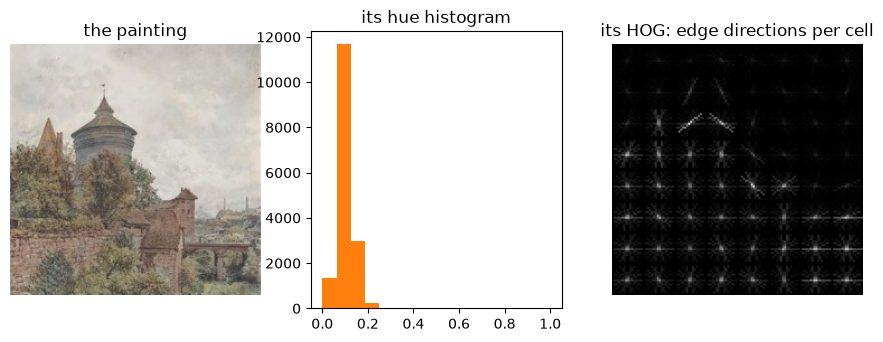

In [3]:
def features(image):
    """The 1,802 handcrafted numbers of one RGB image (uint8, height x width x 3): colour first, then the layout of edges."""
    size = CONFIG["feature_size"]
    small = np.asarray(Image.fromarray(image).resize((size, size), Image.Resampling.BILINEAR))
    hsv = rgb2hsv(small)
    histograms = [np.histogram(hsv[..., k], bins=bins, range=(0, 1))[0] / hsv[..., k].size
                  for k, bins in enumerate(CONFIG["hsv_bins"])]
    moments = np.concatenate([hsv.mean(axis=(0, 1)), hsv.std(axis=(0, 1))])
    cell = CONFIG["hog_cell"]
    edges = hog(rgb2gray(small), orientations=9, pixels_per_cell=(cell, cell), cells_per_block=(2, 2))
    return np.concatenate([*histograms, moments, edges]).astype("float32")


example = split_rows("train").iloc[0]
image = read_image(example["path"])
print("genre:", example["label"], "| numbers per painting:", len(features(image)))

small = np.asarray(Image.fromarray(image).resize((CONFIG["feature_size"],) * 2, Image.Resampling.BILINEAR))
_, edge_picture = hog(rgb2gray(small), orientations=9, pixels_per_cell=(CONFIG["hog_cell"],) * 2, cells_per_block=(2, 2),
                      visualize=True)
hue = rgb2hsv(small)[..., 0]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
axes[0].imshow(image)
axes[0].set_title("the painting")
axes[1].hist(hue.ravel(), bins=CONFIG["hsv_bins"][0], range=(0, 1), color="tab:orange")
axes[1].set_title("its hue histogram")
axes[2].imshow(edge_picture, cmap="gray")
axes[2].set_title("its HOG: edge directions per cell")
for ax in (axes[0], axes[2]):
    ax.axis("off")
plt.show()

## 3. The numbers for the training and validation paintings

About half a minute. The test paintings are not touched yet.

In [4]:
def load_features(split):
    rows = split_rows(split)
    return np.stack([features(read_image(p)) for p in rows["path"]]), rows["label_idx"].to_numpy()


start = time.time()
X_train, y_train = load_features("train")
X_val, y_val = load_features("val")
print(f"train {X_train.shape}, validation {X_val.shape} ({time.time() - start:.0f} s)")
print("all finite:", bool(np.isfinite(X_train).all() and np.isfinite(X_val).all()))

train (1920, 1802), validation (480, 1802) (31 s)
all finite: True


## 4. Models, and the choice on validation

Two families, both classical:
- a **logistic regression**: one weighted sum of the 1,802 numbers per genre (after putting them on the same scale). The only
  setting is `C`, how freely the weights may grow: small `C` means a simpler model;
- a **random forest**: 300 decision trees, each built on a random part of the data, voting together.

Five models in all. The one with the best validation accuracy is the baseline. Chance is 20%.

In [5]:
def candidates():
    models = {f"logistic regression, C={c}": make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=3000))
              for c in CONFIG["logreg_c"]}
    models[f"random forest, {CONFIG['forest_trees']} trees"] = RandomForestClassifier(
        CONFIG["forest_trees"], n_jobs=-1, random_state=CONFIG["seed"])
    return models


fitted, rows = {}, []
for name, model in candidates().items():
    start = time.time()
    model.fit(X_train, y_train)
    fitted[name] = model
    rows.append({"model": name, "train_acc": (model.predict(X_train) == y_train).mean(),
                 "val_acc": (model.predict(X_val) == y_val).mean(), "train_seconds": round(time.time() - start)})

results = pd.DataFrame(rows)
best = results.loc[results["val_acc"].idxmax(), "model"]
display(results.round(3))
print("chosen on validation:", best)

,model,train_acc,val_acc,train_seconds
0,"logistic regression, C=0.001",0.784,0.577,8
1,"logistic regression, C=0.01",0.940,0.542,8
2,"logistic regression, C=0.1",1.000,0.523,11
3,"logistic regression, C=1.0",1.000,0.517,9
4,"random forest, 300 trees",1.000,0.600,3


chosen on validation: random forest, 300 trees


## 5. What the choice tells us

Look at the gap between `train_acc` and `val_acc`. The forest knows its training paintings perfectly (100%) and gets about 60% on
new ones: like the dense network, it **memorises**. The logistic regression is the other way round: the smaller `C`, the less it
memorises and the better it does on validation, up to the limit of what these numbers can say. The best result of this family is
about 60%, a long way from the ResNet.

## 6. Museum B, once

The chosen model, on the 600 paintings of museum B. The check against the recorded score is a reproduction test, not a choice:
if it fails, something changed (data, features, library), and the number would no longer be the one in ADR 0014.

In [6]:
X_test, y_test = load_features("test")
model = fitted[best]
predicted = model.predict(X_test)
test_acc = float((predicted == y_test).mean())
print(f"{best}: accuracy on museum B {test_acc:.1%} (recorded {RECORDED_TEST_ACC:.1%})")
assert abs(test_acc - RECORDED_TEST_ACC) < 0.005, "museum B does not give the recorded score"

random forest, 300 trees: accuracy on museum B 58.5% (recorded 58.5%)


## 7. Where does it go wrong on museum B?

Same reading as P02: rows are the true genre, columns the prediction, the diagonal is what is right.

In [7]:
confusion = pd.crosstab(pd.Series([classes[i] for i in y_test], name="true genre"),
                        pd.Series([classes[i] for i in predicted], name="predicted"))
confusion = confusion.reindex(index=classes, columns=classes, fill_value=0)
per_class = pd.Series({c: confusion.loc[c, c] / confusion.loc[c].sum() for c in classes}, name="accuracy").round(2)
display(confusion)
display(per_class.to_frame())

predicted,cityscape,landscape,portrait,religious_painting,still_life
true genre,,,,,
cityscape,76,26,1,12,5
landscape,19,86,1,11,3
portrait,1,1,81,24,13
religious_painting,13,14,30,48,15
still_life,11,18,14,17,60


,accuracy
cityscape,0.63
landscape,0.72
portrait,0.68
religious_painting,0.40
still_life,0.50


Religious paintings (40% right) are the hardest: they are taken for portraits (30 of 120) and still lifes. A hue histogram and
edge directions cannot tell a Virgin and Child from a portrait; the networks find the same pair hard (ADR 0012), but far less so.

## 8. What it costs on a kiosk

As in P09: milliseconds from the image to the 5 genre scores, **features included**, one image at a time on one CPU thread (median
of 3 rounds over 60 museum B paintings). The forest has its own threads, which `threadpool_limits` does not cover, so we set
`n_jobs=1` for the measurement.

In [8]:
TIMING_IMAGES, TIMING_ROUNDS = 60, 3
images = [read_image(p) for p in split_rows("test")["path"].iloc[:TIMING_IMAGES]]
if hasattr(model, "n_jobs"):
    model.n_jobs = 1

rounds = []
with threadpool_limits(1):
    model.predict(features(images[0])[None])  # warm-up
    for _ in range(TIMING_ROUNDS):
        start = time.perf_counter()
        for image in images:
            model.predict_proba(features(image)[None])
        rounds.append((time.perf_counter() - start) / len(images) * 1000)
    start = time.perf_counter()
    for image in images:
        features(image)
    features_ms = (time.perf_counter() - start) / len(images) * 1000

ms_per_photo = float(np.median(rounds))
size_mb = len(pickle.dumps(model)) / 1e6
print(f"{ms_per_photo:.0f} ms per photo on 1 thread, of which {features_ms:.0f} ms for the features; model {size_mb:.0f} MB")

43 ms per photo on 1 thread, of which 12 ms for the features; model 22 MB


## 9. The ladder

The classical baseline next to our neural networks, all scored on museum B. The accuracies come from `results/experiments.csv`;
the times and sizes are those of P09 (same laptop, same way of measuring).

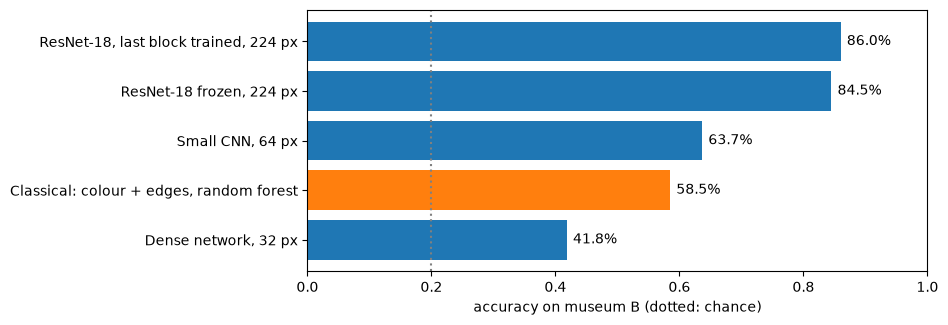

,model,test_acc,ms_per_photo,size_mb
0,"Dense network, 32 px",0.418,0.1,1.6
1,"Classical: colour + edges, random forest",0.585,42.8,22.1
2,"Small CNN, 64 px",0.637,1.7,0.1
3,"ResNet-18 frozen, 224 px",0.845,70.3,44.7
4,"ResNet-18, last block trained, 224 px",0.860,70.5,44.7


In [9]:
runs = summary()
NETWORKS = {"dense_baseline": ("Dense network, 32 px", 0.1, 1.6), "cnn_longer": ("Small CNN, 64 px", 1.7, 0.1),
            "resnet18_head": ("ResNet-18 frozen, 224 px", 70.3, 44.7),
            "resnet18_layer4": ("ResNet-18, last block trained, 224 px", 70.5, 44.7)}  # name -> label, ms (P09), MB (P09)
ladder = [(label, float(runs.loc[runs["name"] == run, "test_acc"].dropna().iloc[0]), ms, mb)
          for run, (label, ms, mb) in NETWORKS.items()]
ladder.append(("Classical: colour + edges, random forest", test_acc, ms_per_photo, size_mb))
ladder = pd.DataFrame(ladder, columns=["model", "test_acc", "ms_per_photo", "size_mb"]).sort_values("test_acc")

fig, ax = plt.subplots(figsize=(8, 3.4))
colors = ["tab:orange" if m.startswith("Classical") else "tab:blue" for m in ladder["model"]]
ax.barh(ladder["model"], ladder["test_acc"], color=colors)
ax.axvline(0.2, color="grey", linestyle=":")
ax.set_xlim(0, 1)
ax.set_xlabel("accuracy on museum B (dotted: chance)")
for y, value in enumerate(ladder["test_acc"]):
    ax.text(value + 0.01, y, f"{value:.1%}", va="center")
plt.show()
display(ladder.round({"test_acc": 3, "ms_per_photo": 1, "size_mb": 1}).reset_index(drop=True))

## What we see

- **A neural network is worth it, but not every one.** The fine-tuned ResNet-18 is **27.5 points** above the classical model, for
  +28 ms and twice the size. The dense network, on the other hand, is 17 points *below* it: flattening 3,072 pixels into a
  network that cannot see neighbours is worse than colours and edges chosen by hand. What pays is pretraining, not "being a network".
- **The small CNN and the forest are close.** On validation they tie (60.0% against 58 to 61%); on museum B the CNN is 5 points ahead,
  a gap near the noise (about +/- 2.9 points on 600 images, for each). But the CNN is 25 times faster and 200 times smaller, so on
  cost it dominates the forest.
- **The forest is slow for what it does**: 300 trees on 1,802 numbers, plus 12 ms just to compute the features. (Times move by 10 to 25% from one run to the next, as in P09: read the ratios.)
- **Limits.** One feature set fixed in advance, one split, a forest tuned only on its size. A better-engineered classical model
  could gain a few points; we did not look for them. The classical model is a reference, not a competitor we tried to beat.

Next: the decision is written in [ADR 0014](../../../adr/0014-classical-baseline.md), and the baseline is the first bar of the ladder
in the demo.

In [10]:
# Record the numbers: the demo reads this file (scripts/build_app.py).
results["chosen"] = results["model"] == best
results["test_acc"] = None
results.loc[results["chosen"], "test_acc"] = round(test_acc, 4)
results["n_features"] = X_train.shape[1]
results["ms_per_photo_1_thread"] = None
results["size_mb"] = None
results.loc[results["chosen"], "ms_per_photo_1_thread"] = round(ms_per_photo, 1)
results.loc[results["chosen"], "size_mb"] = round(size_mb, 2)
results.round(4).to_csv(RESULTS_DIR / "classical_baseline.csv", index=False)
print("wrote results/classical_baseline.csv")

wrote results/classical_baseline.csv
